# Arla × OSCA Forecasting Challenge: forecasting weekly orders, step by step

**Goal.** Forecast `Orders Weekly` for one customer-product series and judge the forecast honestly on weeks the models have not seen.

**Approach.** We follow Lectures 10-12 and start simple, adding one idea at a time. Every new model has to beat the ones before it on the **same 13 holdout weeks**.

| Step | Model | What it adds | Lecture |
|---|---|---|---|
| 1 | Mean, naive, drift, seasonal naive | four frozen patterns: the bar every model must clear | 10 |
| 2 | ARMA(p, q) | learns from the last few weeks | 11 |
| 3 | SARIMA | + the same week one year before (the season) | 12 |
| 4 | SARIMAX | + a promotion indicator (known in advance) | 12 |
| 5 | SARIMAX | + the holiday calendar | 12 |

Before the models: how the data is **checked and cleaned**, and **which variables** we use and why.
After the models: checks of the result, and in Part 10 what happens if we forecast **half a year (26 weeks)** ahead.

Run the cells from top to bottom (in PyCharm: the run button, or Shift+Enter). The data file must sit next to this notebook. The whole notebook runs in about 1-2 minutes.

## Setup: imports and the helpers from Lecture 10

The same helpers as in the lecture notebooks: `split_holdout`, `mae`, `rmse`, `mase`. The only change: the holdout is **13 weeks** (one quarter), not 12. Part 4 explains why.

In [1]:
import datetime as dt
from itertools import product                                       # every combination of several ranges (Lecture 12)
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf           # the ADF test; autocorrelations as numbers
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf       # the two plots (Lecture 9 and 11)
from statsmodels.tsa.seasonal import STL                            # the decomposition (Lecture 10)
from statsmodels.tsa.statespace.sarimax import SARIMAX              # one class for every model of Lectures 11-12
from statsmodels.stats.diagnostic import acorr_ljungbox             # the Ljung-Box test
import warnings
warnings.filterwarnings("ignore")     # statsmodels prints convergence notes; after its imports, this line silences them

H = 13   # frozen holdout: the LAST 13 WEEKS of the series
RESULTS = Path("results")             # the few files we save go here
RESULTS.mkdir(exist_ok=True)

def split_holdout(weekly, h=H):
    return weekly.iloc[:-h], weekly.iloc[-h:]

def mae(actual, fc):  return float(np.mean(np.abs(np.asarray(actual) - np.asarray(fc))))
def rmse(actual, fc): return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(fc)) ** 2)))
def mase(actual, fc, train):
    scale = float(np.mean(np.abs(np.diff(np.asarray(train)))))   # in-sample one-step naive MAE
    return mae(actual, fc) / scale

# Part 1: The data and how we clean it

## Load the file and look at it

**The question.** Is the file what the assignment PDF describes? (The PDF calls it `Forecast_OSCA.xlsx`; our copy is `Forecasting_challenge_data.xlsx`.)

In [2]:
DATA_FILE = Path("Forecasting_challenge_data.xlsx")   # the data file from the course, next to this notebook
assert DATA_FILE.exists(), "Put Forecasting_challenge_data.xlsx (from the course) in the same folder as this notebook"
xls = pd.ExcelFile(DATA_FILE)
xls.sheet_names                      # which sheets does the file have?

['Sheet1']

In [3]:
raw = pd.read_excel(xls, sheet_name="Sheet1")
print(raw.shape)                     # rows, columns
raw.iloc[:6, :8]                     # the first rows and the first columns

(800, 162)


,Customer,Product,Product Category 1,Product Category 2,Key Figure,W34 2023,W35 2023,W36 2023
0,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Orders Weekly,1657.7088,1193.048,1846.0848
1,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Exception Week,0.0000,0.000,0.0000
2,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Manual Cleaned History,0.0000,0.000,0.0000
3,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Weekly Promotion Adjustments,0.0000,0.000,0.0000
4,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Promotion Adjustment,0.0000,0.000,0.0000
5,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Maundy Thursday Calendar,0.0000,0.000,0.0000


In [4]:
id_cols = list(raw.columns[:5])      # who and what: customer, product, two categories, Key Figure
week_cols = list(raw.columns[5:])    # one column per week
print(id_cols)
print(len(week_cols), "week columns, from", week_cols[0], "to", week_cols[-1])
raw["Key Figure"].value_counts()     # the 16 rows of every series

['Customer', 'Product', 'Product Category 1', 'Product Category 2', 'Key Figure']
157 week columns, from W34 2023 to W34 2026


Key Figure
Orders Weekly                   50
Exception Week                  50
Manual Cleaned History          50
Weekly Promotion Adjustments    50
Promotion Adjustment            50
Maundy Thursday Calendar        50
New Year Calendar               50
Easter Monday Calendar          50
Seasonality Calendar 1          50
Seasonality Calendar 2          50
Seasonality Calendar 4          50
Seasonality Calendar 3          50
Seasonality Calendar 5          50
Seasonality Calendar 6          50
Seasonality Calendar 7          50
Seasonality Calendar 8          50
Name: count, dtype: int64

**What to see.** One sheet, 800 rows and 162 columns. The data is **wide**: every row is one combination of customer, product and Key Figure, and the 157 weeks run from W34 2023 to W34 2026 as columns. Each of the 16 Key Figures appears 50 times: **50 customer-product series**, each with 16 rows.

## Data checks

**The question.** Are there duplicates, missing values or strange values that we must clean before we model?

In [5]:
print("customer-product series:", raw.groupby(["Customer", "Product"]).ngroups)
print("duplicate rows (customer, product, Key Figure):", raw.duplicated(["Customer", "Product", "Key Figure"]).sum())
print("missing values in the week columns:", raw[week_cols].isna().sum().sum())
# negative values, counted per Key Figure (only the Key Figures that have any)
neg = (raw[week_cols] < 0).sum(axis=1).groupby(raw["Key Figure"]).sum()
neg[neg > 0]

customer-product series: 50
duplicate rows (customer, product, Key Figure): 0
missing values in the week columns: 0


Key Figure
Promotion Adjustment            17
Weekly Promotion Adjustments    24
dtype: int64

**What to see.** 50 series, no duplicates and no missing values. So nothing has to be filled in or deleted. Negative values appear only in the two promotion rows. That is no problem, because we will only use those rows as yes/no (Part 2). `Orders Weekly` has no negative values.

**Zeros.** A week with 0 orders is a real week without orders, not a missing value. We keep zeros as zeros and never turn them into NaN.

## From week labels to dates

**The question.** The weeks are text (`"W34 2023"`). A time series needs real dates. We use the Monday of each ISO week, and we check that the weeks follow each other with no gaps.

In [6]:
def week_to_date(label):
    """'W34 2023' -> the Monday of ISO week 34 in 2023."""
    week, year = label.split()
    return pd.Timestamp(dt.date.fromisocalendar(int(year), int(week[1:]), 1))

dates = pd.Series([week_to_date(w) for w in week_cols])
print(dates.iloc[0].date(), "to", dates.iloc[-1].date())
print("in order, and always exactly 7 days apart:", dates.is_monotonic_increasing and (dates.diff().dropna().dt.days == 7).all())

2023-08-21 to 2026-08-17
in order, and always exactly 7 days apart: True


## Wide to long: one row per week

**The question.** How do we turn the wide sheet into time series? `melt` turns the 157 week columns into rows (one row per series, Key Figure and week). The helper `get_series` then picks one customer-product series, with the weeks as rows and the 16 Key Figures as columns.

In [7]:
long = raw.melt(id_vars=id_cols, value_vars=week_cols, var_name="week", value_name="value")
long["date"] = long["week"].map(week_to_date)
print(len(long), "rows = 50 series x 16 Key Figures x 157 weeks")
long.head(3)

125600 rows = 50 series x 16 Key Figures x 157 weeks


,Customer,Product,Product Category 1,Product Category 2,Key Figure,week,value,date
0,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Orders Weekly,W34 2023,1657.7088,2023-08-21
1,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Exception Week,W34 2023,0.0000,2023-08-21
2,Discount 1,Product 1,Other Fermented,Other Fermented Flavoured,Manual Cleaned History,W34 2023,0.0000,2023-08-21


In [8]:
def get_series(customer, product):
    """All 16 Key Figures of one customer-product series: one row per week, one column per Key Figure."""
    rows = long[(long["Customer"] == customer) & (long["Product"] == product)]
    table = rows.pivot(index="date", columns="Key Figure", values="value")
    return table.asfreq("W-MON")     # weekly dates (Mondays); a missing week would show up as NaN

# Part 2: The 16 Key Figures and which ones we use

From the assignment PDF:

| Key Figure | Meaning (PDF) |
|---|---|
| Orders Weekly | the demand in the week: **the target** |
| Exception Week | a manual flag by Arla's planners when something unusual affected demand |
| Manual Cleaned History | a figure planners were told to use instead of the observed demand |
| Weekly Promotion Adjustments, Promotion Adjustment | the size of the uplift Arla adds to its baseline forecast in a promotion week |
| Maundy Thursday / New Year / Easter Monday Calendar | 1 if the holiday falls in the week |
| Seasonality Calendar 1-8 | 1 if the week matches a seasonal pattern; **the seasons are not specified** |

## The calendar rows

**The question.** Are the calendar rows the same for every series, and when are they 1?

In [9]:
calendar_rows = ["Maundy Thursday Calendar", "New Year Calendar", "Easter Monday Calendar"] + \
                [f"Seasonality Calendar {i}" for i in range(1, 9)]
info = {}
for name in calendar_rows:
    rows = raw.loc[raw["Key Figure"] == name, week_cols]
    info[name] = {"same in all 50 series": bool((rows.nunique() == 1).all()),
                  "weeks with a 1": [w for w in week_cols if rows[w].iloc[0] == 1]}
pd.DataFrame(info).T

,same in all 50 series,weeks with a 1
Maundy Thursday Calendar,True,"[W13 2024, W16 2025, W14 2026]"
New Year Calendar,True,"[W52 2023, W01 2025, W01 2026]"
Easter Monday Calendar,True,"[W14 2024, W17 2025, W15 2026]"
Seasonality Calendar 1,True,"[W01 2024, W01 2025, W01 2026]"
Seasonality Calendar 2,True,"[W19 2024, W22 2025, W20 2026]"
Seasonality Calendar 3,True,[]
Seasonality Calendar 4,True,"[W45 2023, W46 2024, W46 2025]"
Seasonality Calendar 5,True,"[W20 2024, W23 2025, W21 2026]"
Seasonality Calendar 6,True,"[W21 2024, W24 2025, W22 2026]"
Seasonality Calendar 7,True,"[W50 2023, W51 2024, W51 2025]"


**What to see.** Every calendar row is the same for all 50 series and is 1 in three weeks, one per year. **Seasonality Calendar 3 is never 1** (all zeros), so it carries no information and we drop it. The other seasonality calendars move a little from year to year, but the PDF does not say what they mean. We do not guess. Each one is also 1 only three times, so we leave them out to keep the model simple and easy to explain. The three holidays have a clear meaning and are known in advance, so we test them in Model 5.

## Exception Week

**The question.** What values does the flag take?

In [10]:
raw.loc[raw["Key Figure"] == "Exception Week", week_cols].stack().value_counts()

0.0    6799
1.0     621
2.0     430
Name: count, dtype: int64

**What to see.** Only 0, 1 and 2: a flag (a category), not an amount. The PDF does not explain the difference between 1 and 2, so we only read it as "a planner marked this week". Planners set the flag **after** the week, so it is **not known for future weeks** and cannot be an input to a forecast. We **keep** the flagged weeks (we delete nothing) and use the flags only to understand large errors.

## Promotions

The PDF says: treat a promotion as a **category, not a volume**. We may use whether there is a promotion, but not the size of the uplift. The timing of promotions is known in advance, so the indicator may also be used for the holdout weeks. Our indicator: `promo = 1` if either of the two promotion rows is different from 0.

# Part 3: Which series do we forecast?

**The question.** Which of the 50 series should we work on? We decide the holdout first (the last 13 weeks), so that **even the choice of series uses only the 144 training weeks**.

Our criteria:
1. **Dense**: at most 5% zero weeks. ARMA/SARIMA and STL make little sense when most weeks are 0.
2. **Has promotions**: promotion weeks in 10-90% of the weeks, so the promotion indicator varies and we can learn from it. Promotions are one of the main difficulties Arla mentions.
3. Among those: the **highest average orders** (the most important series for the business).

In [11]:
train_weeks = week_cols[:-H]           # the first 144 weeks; the last 13 are the holdout
rows = []
for (customer, prod), g in raw.groupby(["Customer", "Product"]):
    kf = g.set_index("Key Figure")[train_weeks]          # the 16 rows of this series, training weeks only
    orders = kf.loc["Orders Weekly"]
    is_promo = (kf.loc["Weekly Promotion Adjustments"] != 0) | (kf.loc["Promotion Adjustment"] != 0)
    rows.append({"customer": customer, "product": prod, "category": g["Product Category 2"].iloc[0],
                 "mean orders": orders.mean(), "share zero weeks": (orders == 0).mean(),
                 "share promo weeks": is_promo.mean()})
overview = pd.DataFrame(rows).sort_values("mean orders", ascending=False)
print("sparse series (more than 5% zero weeks):", (overview["share zero weeks"] > 0.05).sum(), "of 50")
overview.head(8).round(2)

sparse series (more than 5% zero weeks): 14 of 50


,customer,product,category,mean orders,share zero weeks,share promo weeks
8,Discount 2,Product 4,Conventional milk fresh,29790.06,0.00,0.00
5,Discount 1,Product 6,Conventional milk fresh,28974.33,0.00,0.00
10,Discount 2,Product 6,Conventional milk fresh,28118.75,0.00,0.00
3,Discount 1,Product 4,Conventional milk fresh,27728.91,0.00,0.00
2,Discount 1,Product 3,Skyr Flavoured,15946.42,0.00,0.28
7,Discount 2,Product 3,Skyr Flavoured,15469.57,0.01,0.53
15,Discount 3,Product 4,Conventional milk fresh,13116.07,0.00,0.00
17,Discount 3,Product 6,Conventional milk fresh,12786.84,0.00,0.00


In [12]:
candidates = overview[(overview["share zero weeks"] <= 0.05) & overview["share promo weeks"].between(0.10, 0.90)]
candidates.head(5).round(2)

,customer,product,category,mean orders,share zero weeks,share promo weeks
2,Discount 1,Product 3,Skyr Flavoured,15946.42,0.00,0.28
7,Discount 2,Product 3,Skyr Flavoured,15469.57,0.01,0.53
9,Discount 2,Product 5,Other Fermented Plain,8950.59,0.00,0.17
16,Discount 3,Product 5,Other Fermented Plain,7999.24,0.00,0.28
14,Discount 3,Product 3,Skyr Flavoured,6774.80,0.00,0.44


**What to see.** 14 of the 50 series are sparse (more than 5% zero weeks). The largest series overall (conventional milk) have no promotions. Among the dense series with promotions, the largest is **Discount 1 – Product 3 (Skyr Flavoured)**: no zero weeks, promotions in 28% of the weeks, and on average about 15,900 orders a week. That is our series.

# Part 4: The clean dataset for our series

**Why 13 holdout weeks?** 13 weeks is one quarter, a natural planning horizon. It leaves 144 training weeks (2.8 years). That is still two full years, which the seasonal methods need: the seasonal naive looks 52 weeks back, STL needs at least two cycles, and a seasonal difference uses up the first 52 weeks.

In [13]:
s = get_series("Discount 1", "Product 3")
print("missing weeks or values:", s.isna().sum().sum())

y = s["Orders Weekly"]                                                    # the target; zeros would stay zeros
promo = ((s["Weekly Promotion Adjustments"] != 0) | (s["Promotion Adjustment"] != 0)).astype(int)  # yes/no only
holidays = s[["Maundy Thursday Calendar", "New Year Calendar", "Easter Monday Calendar"]]
exception = s["Exception Week"]                                           # only to understand errors later
mch = s["Manual Cleaned History"]                                         # looked at below

train, test = split_holdout(y)
print("training:", len(train), "weeks,", train.index[0].date(), "to", train.index[-1].date())
print("holdout: ", len(test), "weeks,", test.index[0].date(), "to", test.index[-1].date())
print("zero weeks in training:", int((train == 0).sum()))
print("promotion weeks: training", promo[train.index].sum(), "| holdout", promo[test.index].sum())

missing weeks or values: 0
training: 144 weeks, 2023-08-21 to 2026-05-18
holdout:  13 weeks, 2026-05-25 to 2026-08-17
zero weeks in training: 0
promotion weeks: training 41 | holdout 1


## Manual Cleaned History: replace the orders or not?

**The question.** The PDF says planners were sometimes told to use another figure for the demand. If the row is not 0, the value is that other figure. Should we put it into the training data instead of the actual orders?

In [14]:
changed = pd.DataFrame({"orders": train, "cleaned value": mch[train.index],
                        "promo": promo[train.index], "exception": exception[train.index]})
changed = changed[changed["cleaned value"] != 0]          # the weeks a planner changed
print(len(changed), "training weeks have a cleaned value;", changed["promo"].sum(), "of them are promotion weeks")
changed.groupby("promo")[["orders", "cleaned value"]].mean().round(0)   # average without (0) and with (1) promotion

35 training weeks have a cleaned value; 13 of them are promotion weeks


,orders,cleaned value
promo,,
0,6481.0,6609.0
1,43743.0,7114.0


**What to see.** In promotion weeks, the cleaned value (about 7,100) replaces peaks of about 43,700. The planners **remove the promotion effect** and keep a baseline. In normal weeks the change is small (6,481 to 6,609).

**Our decision.** We keep the **raw `Orders Weekly`**. Our models learn the promotion effect from a promotion indicator. If 13 of the promotion peaks were replaced by the baseline, the model would see promotions with and without an effect, which is inconsistent. We test this decision at the end (Part 9). The holdout is always scored against the raw orders, because that is the demand we want to forecast.

## The variables we use

| Key Figure | Decision | Why |
|---|---|---|
| Orders Weekly | **target**, raw | the demand to forecast; zeros stay zeros |
| Weekly Promotion Adjustments, Promotion Adjustment | **one yes/no promotion indicator** | the size must not be used (PDF); the timing is known in advance |
| Maundy Thursday, New Year, Easter Monday | **tested** in Model 5 | known in advance |
| Seasonality Calendar 1-8 | not used | meaning not given; Calendar 3 is all zeros; each is 1 only three times |
| Exception Week | not an input; flagged weeks are **kept** | set after the fact, unknown for future weeks |
| Manual Cleaned History | not used | removes the promotion peaks; checked in Part 9 |

# Part 5: Look at the series before we model it

**The question.** What does the series look like: a trend, a season, peaks? We only plot the **training weeks**, so the holdout cannot influence our choices.

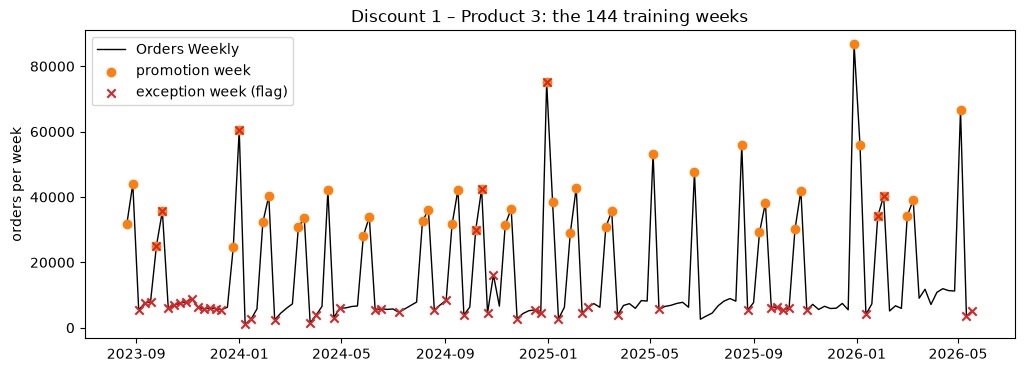

0     6272.0
1    40251.0
Name: Orders Weekly, dtype: float64

In [15]:
is_promo = promo[train.index] == 1
is_flag = exception[train.index] > 0
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train, color="black", lw=1, label="Orders Weekly")
ax.scatter(train.index[is_promo], train[is_promo], color="tab:orange", zorder=3, label="promotion week")
ax.scatter(train.index[is_flag], train[is_flag], marker="x", color="tab:red", zorder=3, label="exception week (flag)")
ax.set_title("Discount 1 – Product 3: the 144 training weeks"); ax.set_ylabel("orders per week"); ax.legend()
plt.show()
train.groupby(promo[train.index]).mean().round(0)       # mean orders without (0) and with (1) a promotion

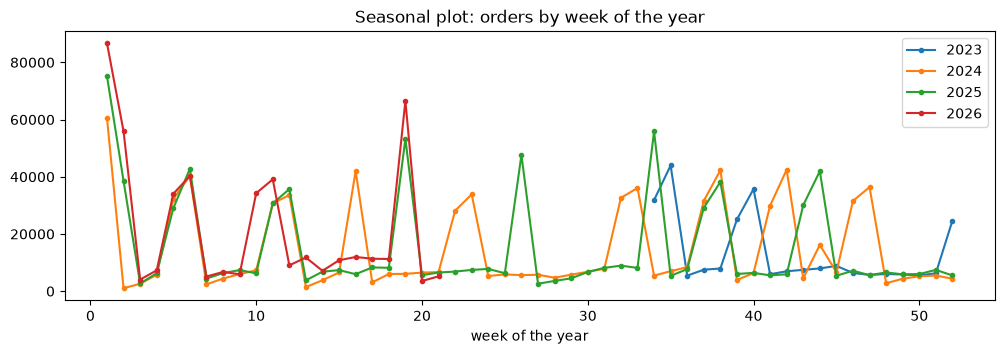

In [16]:
# the seasonal plot (Lecture 9): orders against the week of the year, one line per year
iso = train.index.isocalendar()                         # ISO year and ISO week of every date
fig, ax = plt.subplots(figsize=(12, 3.5))
for year in [2023, 2024, 2025, 2026]:
    in_year = iso["year"] == year
    ax.plot(iso["week"][in_year], train[in_year], marker="o", ms=3, label=str(year))
ax.set_title("Seasonal plot: orders by week of the year"); ax.set_xlabel("week of the year"); ax.legend()
plt.show()

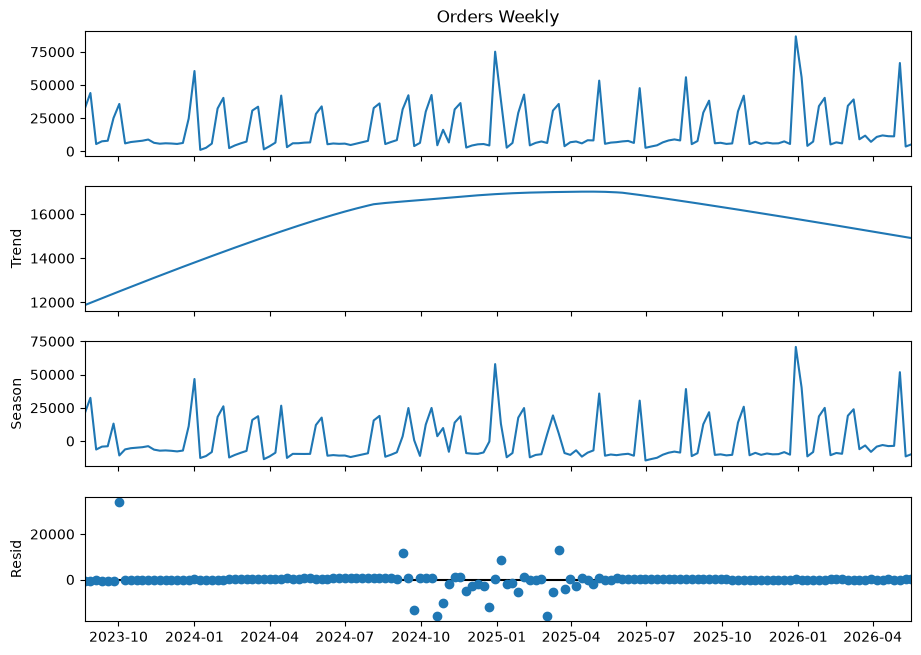

In [17]:
stl = STL(train, period=52, robust=True).fit()          # Lecture 10; robust=True: odd weeks pull less
fig = stl.plot()
fig.set_size_inches(10, 7)
plt.show()

**What to see.**
- A base level of about **6,300 orders** a week, and **promotion peaks of 30,000-87,000**. On average a promotion week has 40,251 orders against 6,272 otherwise. The promotions are the main story of this series.
- The seasonal plot shows that **many peaks fall in the same weeks each year** (for example weeks 1, 5-6, 11-12, 19 and 37-38): Arla's promotion calendar partly repeats. So we can expect a yearly pattern (a season of 52 weeks). But some peaks move (2024: weeks 16 and 23; 2025: week 26), and a pure season cannot know that. The promotion indicator can.
- STL: no strong trend. The seasonal part copies the repeating peaks, and the remainder is large in promotion weeks. With fewer than three years of data the seasonal part is uncertain.
- Exception weeks (red crosses) appear both in normal weeks and next to peaks. We keep them.

# Model 1: four baselines (Lecture 10)

**The question.** How good are the simplest forecasts? Each one freezes one pattern of the past. Every later model must beat them.

In [18]:
h = np.arange(1, H + 1)                                 # the horizons 1, 2, ..., 13
forecasts = {"mean": np.repeat(train.mean(), H),
             "naive": np.repeat(train.iloc[-1], H),
             "drift": train.iloc[-1] + h * (train.iloc[-1] - train.iloc[0]) / (len(train) - 1),
             "seasonal naive": train.iloc[-52:].iloc[:H].values}     # the same 13 weeks one year earlier

def score_table(forecasts):
    """MAE, RMSE and MASE of every forecast on the same 13 holdout weeks."""
    return pd.DataFrame([{"method": m, "MAE": mae(test, f), "RMSE": rmse(test, f), "MASE": mase(test, f, train)}
                         for m, f in forecasts.items()]).set_index("method")

score_table(forecasts).round(3)

,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513


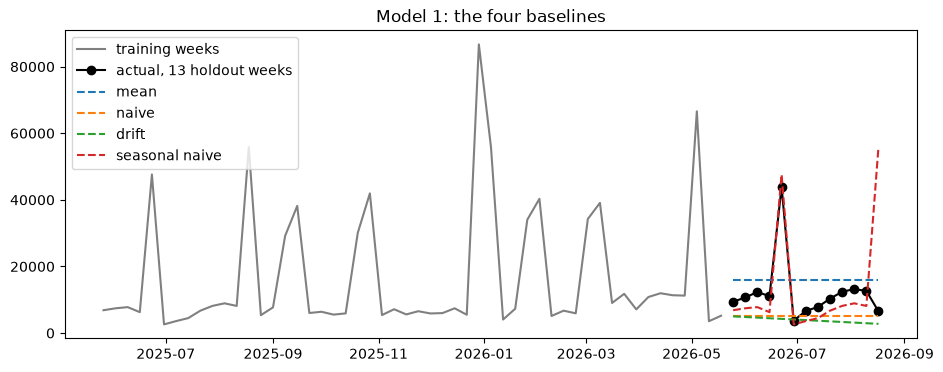

In [19]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.iloc[-52:], color="grey", label="training weeks")
ax.plot(test, marker="o", color="black", label="actual, 13 holdout weeks")
for name, f in forecasts.items():
    ax.plot(test.index, f, ls="--", label=name)
ax.set_title("Model 1: the four baselines"); ax.legend()
plt.show()

**What to see.** The **seasonal naive** is the best baseline (MASE 0.513). It copies last year's weeks, including a promotion peak in week 26. Naive (0.534) and mean (0.570) are close, and drift is the worst (0.616).

**Why MAE, RMSE and MASE (and not MAPE)?** MAE is the typical miss in orders, and RMSE punishes the big misses more. MASE divides the MAE by the average week-to-week change in the training weeks (13,844 orders), so a MASE below 1 means "better than a one-week naive forecast". MAPE divides by the actual value and breaks when there are weeks with 0 orders, which many of the series have.

# Model 2: ARMA, learning from the last weeks (Lecture 11)

## Step 1: is the series stationary? (the ADF test)

The ADF loop from Lecture 12: test, and difference until the p-value is below 0.05.

In [20]:
x = train
for d in range(3):                              # d = 0, 1, 2: at most two differences
    if adfuller(x)[1] < 0.05:                   # [1] = the p-value; below 0.05 = stationary
        break
    x = x.diff().dropna()                       # not stationary yet: one more difference
print("d =", d, "| ADF p-value of the series itself:", adfuller(train)[1])

d = 0 | ADF p-value of the series itself: 2.780780667390581e-15


**What to see.** p is almost 0, so the series is already stationary: **d = 0**. The level does not wander away; it returns to the base level after every peak. So ARIMA(p, 0, q) is the same as ARMA(p, q).

One difference from the lecture: there we modelled the weekly *changes*, whose mean is about 0. Here we model the orders themselves, whose mean is about 15,900. So the model needs the constant $C$ from Lecture 11's equation: `trend="c"`. Like in Lecture 12, we fit in thousands (`train / 1000`) and multiply the forecast by 1,000.

## Step 2: the candidates from ACF and PACF

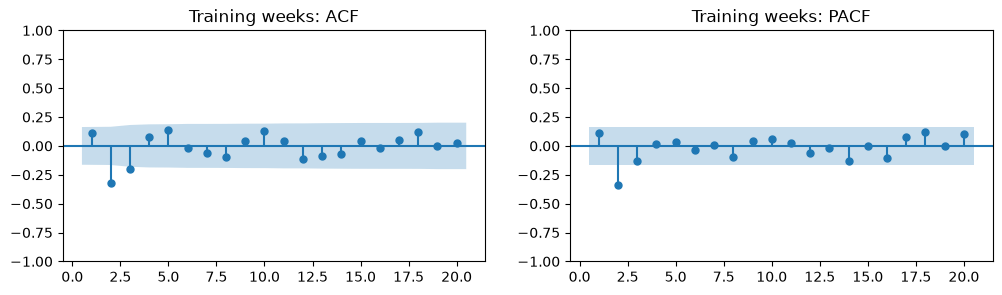

band +/- 0.16


,ACF,PACF
1,0.12,0.12
2,-0.32,-0.34
3,-0.20,-0.13
4,0.08,0.02


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(train, lags=20, ax=axes[0], zero=False, title="Training weeks: ACF")
plot_pacf(train, lags=20, ax=axes[1], zero=False, title="Training weeks: PACF")
plt.show()
band = 1.96 / np.sqrt(len(train))               # the band of Lecture 9
print("band +/-", round(band, 2))
pd.DataFrame({"ACF": acf(train, nlags=4)[1:], "PACF": pacf(train, nlags=4)[1:]}, index=[1, 2, 3, 4]).round(2)

**What to see.** The clearest bar is at **lag 2 and it is negative** (ACF −0.32, PACF −0.34): two weeks after a peak, orders are low, after the promotion stock has been bought. Neither plot stops cleanly, so we try ARMA(p, q) with p and q from 0 to 3 and let the AIC rank them, like in Lecture 11.

## Steps 3 and 4: fit every candidate, keep the lowest AIC

In [22]:
train_k = train / 1000                          # orders in thousands (Lecture 12)
rows = []
for p in range(4):
    for q in range(4):
        fit = SARIMAX(train_k, order=(p, 0, q), trend="c").fit(disp=False)   # trend="c": the constant C
        rows.append({"p": p, "q": q, "AIC": fit.aic})
pd.DataFrame(rows).sort_values("AIC").head(5).round(1)

,p,q,AIC
12,3,0,1212.3
8,2,0,1212.8
9,2,1,1212.8
10,2,2,1214.0
13,3,1,1214.2


**What to see.** The lowest AIC is **ARMA(3, 0)**, an AR(3): three past weeks, no past errors. ARMA(2, 0) and ARMA(2, 1) are almost as good, so the choice is not sharp.

## Step 5: are the residuals white noise?

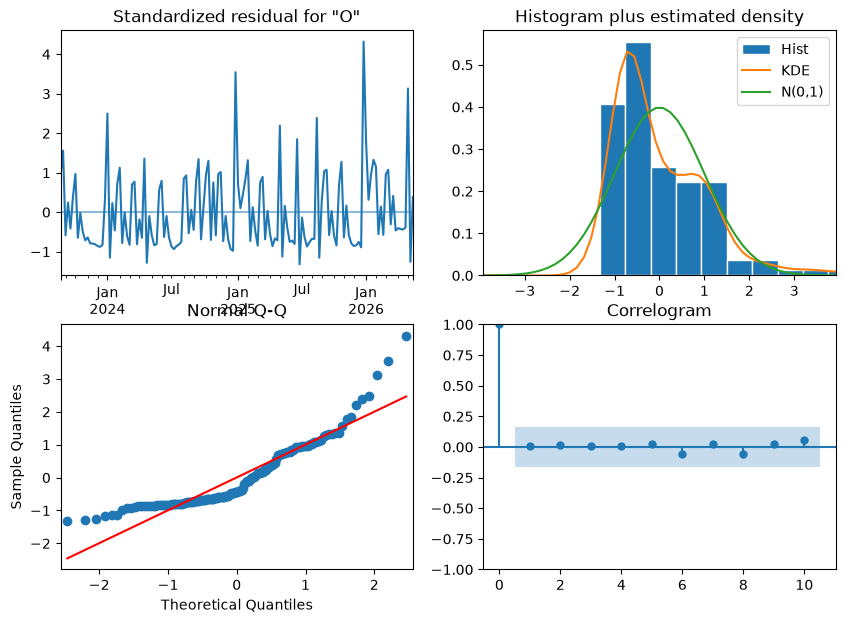

smallest Ljung-Box p-value, lags 1-10: 0.936


In [23]:
arma_order = (3, 0, 0)
arma = SARIMAX(train_k, order=arma_order, trend="c").fit(disp=False)
arma.plot_diagnostics(figsize=(10, 7))
plt.show()
print("smallest Ljung-Box p-value, lags 1-10:", round(acorr_ljungbox(arma.resid, lags=np.arange(1, 11))["lb_pvalue"].min(), 3))

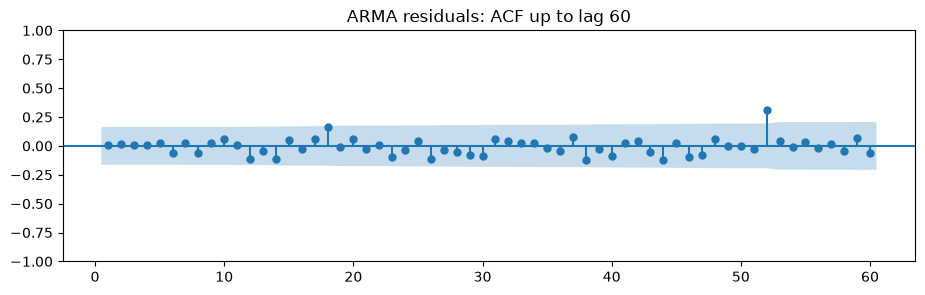

residual autocorrelation at lag 52: 0.31 | band +/- 0.16


In [24]:
fig, ax = plt.subplots(figsize=(11, 3))
plot_acf(arma.resid, lags=60, ax=ax, zero=False, title="ARMA residuals: ACF up to lag 60")
plt.show()
print("residual autocorrelation at lag 52:", round(acf(arma.resid, nlags=52)[52], 2), "| band +/-", round(band, 2))

**What to see.** Ljung-Box passes (smallest p-value 0.94), but the histogram and the Q-Q plot are far from normal: the promotion peaks give huge positive residuals. And there is a **tall bar at lag 52 (0.31)**: a week is related to the same week one year before. That is the yearly pattern we saw in the seasonal plot, exactly as in Lecture 11.

## Step 6: the forecast, with an 80% prediction interval (Lecture 12)

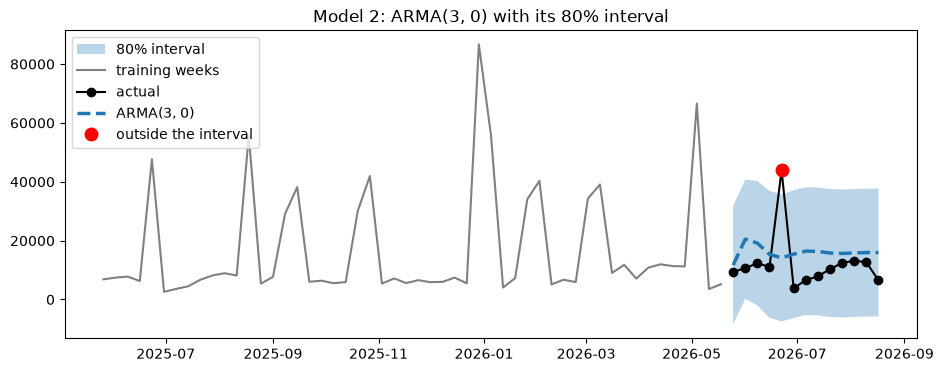

holdout weeks inside the 80% interval: 12 of 13


,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513
"ARMA(3, 0)",8224.031,10750.712,0.594


In [25]:
def band_plot(f, label, title, save_as=None):
    """A fitted model's forecast with its 80% interval, in orders, against the holdout."""
    ci = 1000 * f.conf_int(alpha=0.2)                                   # alpha = 0.2: an 80% interval
    outside = (test < ci.iloc[:, 0]) | (test > ci.iloc[:, 1])           # the holdout weeks outside the interval
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.3, label="80% interval")
    ax.plot(train.iloc[-52:], color="grey", label="training weeks")
    ax.plot(test, marker="o", color="black", label="actual")
    ax.plot(1000 * f.predicted_mean, ls="--", lw=2.5, label=label)
    ax.plot(test[outside], "o", color="red", ms=9, label="outside the interval")
    ax.set_title(title); ax.legend(loc="upper left")
    if save_as:
        fig.savefig(save_as, dpi=130, bbox_inches="tight")
    plt.show()
    print("holdout weeks inside the 80% interval:", int((~outside).sum()), "of", H)

f_arma = arma.get_forecast(H)
forecasts["ARMA(3, 0)"] = 1000 * f_arma.predicted_mean.values
band_plot(f_arma, "ARMA(3, 0)", "Model 2: ARMA(3, 0) with its 80% interval")
score_table(forecasts).round(3)

**What to see.** The ARMA forecast moves for a few weeks and then settles at the mean. Its MASE (0.594) is **worse than the seasonal naive and even the mean**. That is not surprising: the last few weeks cannot tell the model *when* the next promotion comes. The interval is very wide, because the residuals include the peaks.

# Model 3: SARIMA, adding the yearly season (Lecture 12)

## Is there a season, and how do we choose D?

The three ways of Lecture 12: the seasonal plot (Part 5: peaks in the same weeks every year), the ACF of the raw data at lag 52, and STL (Part 5).

In [26]:
print("ACF of the orders at lags 51, 52, 53:", acf(train, nlags=53)[51:54].round(2), "| band +/-", round(band, 2))
print("ADF p-value after one seasonal difference, train.diff(52):", adfuller(train.diff(52).dropna())[1])

ACF of the orders at lags 51, 52, 53: [-0.02  0.31  0.09] | band +/- 0.16
ADF p-value after one seasonal difference, train.diff(52): 1.2299237977181186e-13


**What to see.** A bump at lag 52 (0.31, above the band and above its neighbours). The three ways agree: **m = 52 and D = 1**. After the seasonal difference the series is still stationary, so **d = 0**. The model is SARIMA(p, 0, q)(P, 1, Q)<sub>52</sub>. No constant this time: the seasonal difference removes the level.

## The candidates: ACF and PACF after the seasonal difference

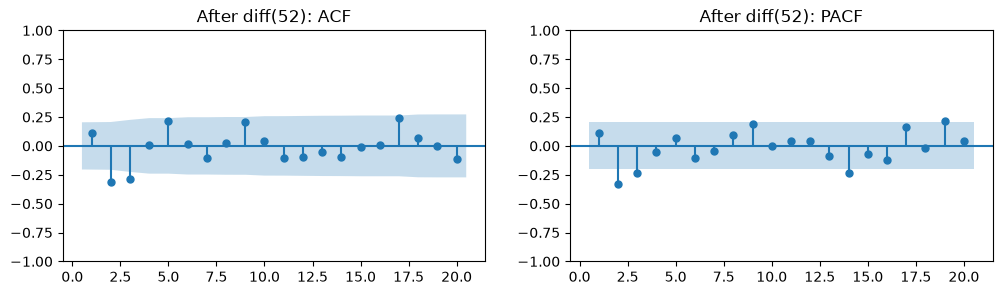

In [27]:
sdiff = train.diff(52).dropna()                 # this week minus the same week one year before: 92 weeks
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(sdiff, lags=20, ax=axes[0], zero=False, title="After diff(52): ACF")
plot_pacf(sdiff, lags=20, ax=axes[1], zero=False, title="After diff(52): PACF")
plt.show()

**What to see.** Bars at lags 2 and 3 in both plots, then mostly small. We try **p = 0 to 3** and **q = 0 or 1**. For the season we try **P, Q = 0 or 1**: with fewer than three years, each week of the year appears only two or three times (the same reasoning as in Lecture 12). That gives 4 × 2 × 2 × 2 = 32 candidates, which takes about half a minute.

In [28]:
aics = {}                                        # the AIC of every candidate, under the key (p, q, P, Q)
for p, q, P, Q in product(range(4), range(2), (0, 1), (0, 1)):
    res = SARIMAX(train_k, order=(p, 0, q), seasonal_order=(P, 1, Q, 52)).fit(disp=False)
    aics[(p, q, P, Q)] = res.aic
pd.Series(aics, name="AIC").sort_values().round(1).head(6)

3  0  0  1    779.2
      1  0    779.2
      0  0    779.5
2  1  1  0    780.7
      0  1    780.7
         0    780.9
Name: AIC, dtype: float64

smallest Ljung-Box p-value, lags 1-10: 0.853


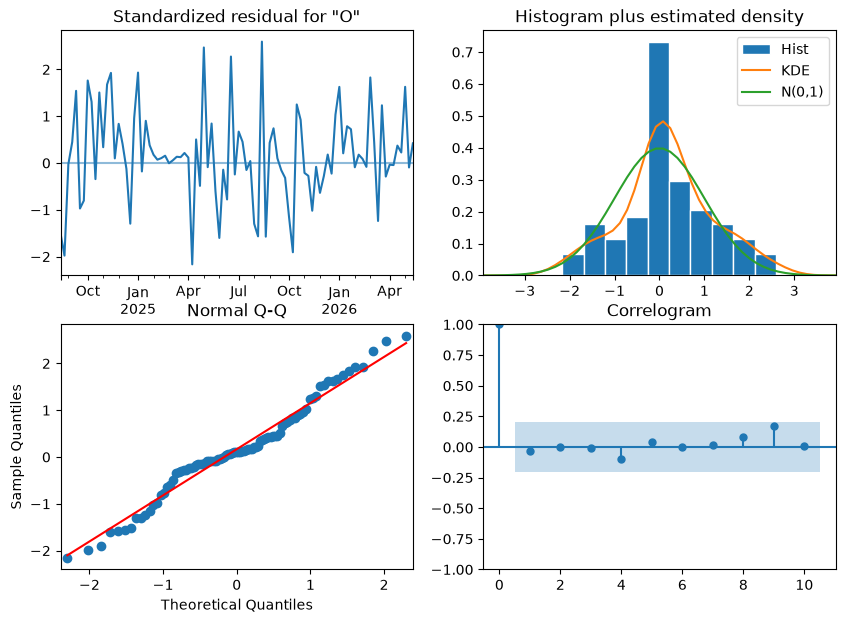

In [29]:
sarima_order, seasonal_order = (3, 0, 0), (0, 1, 1, 52)        # the lowest AIC above
sarima = SARIMAX(train_k, order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
# the first 52 residuals are start-up values of the seasonal difference, not errors of the model: .iloc[52:]
resid = sarima.resid.iloc[52:]
print("smallest Ljung-Box p-value, lags 1-10:", round(acorr_ljungbox(resid, lags=np.arange(1, 11))["lb_pvalue"].min(), 3))
sarima.plot_diagnostics(figsize=(10, 7))
plt.show()

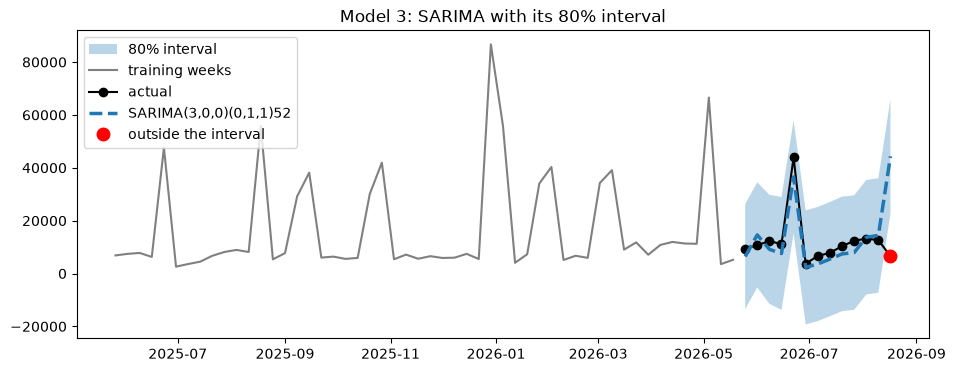

holdout weeks inside the 80% interval: 12 of 13


,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513
"ARMA(3, 0)",8224.031,10750.712,0.594
SARIMA,5785.208,11019.979,0.418


In [30]:
f_sarima = sarima.get_forecast(H)
forecasts["SARIMA"] = 1000 * f_sarima.predicted_mean.values
band_plot(f_sarima, "SARIMA(3,0,0)(0,1,1)52", "Model 3: SARIMA with its 80% interval")
score_table(forecasts).round(3)

**What to see.** The lowest AIC is SARIMA(3, 0, 0)(0, 1, 1)<sub>52</sub>, and its residuals pass Ljung-Box. **The season helps a lot**: MASE falls from 0.594 (ARMA) to **0.418**, better than every baseline. The forecast "remembers" last year's peak in week 26 and gets this year's week-26 promotion roughly right (about 36,500 forecast against 43,900 actual). It also predicts a peak in the last week (W34), because last year's W34 was a promotion week. Part 8 comes back to that.

# Model 4: SARIMAX, adding the promotion indicator (Lecture 12)

**The question.** The SARIMA only knows *last year's* promotions. Arla knows its *own* promotion plan in advance. Does it help to tell the model which weeks have a promotion?

**The caveat of SARIMAX (Lecture 12).** An external variable may only be used if its future values are known when we forecast. The promotion timing is known in advance (PDF), and we use only yes/no, never the size.

In [31]:
X = promo.to_frame("promo")                     # one column, one value per week: 1 = promotion week
X.loc[test.index].T                             # the promotion plan of the 13 holdout weeks: known in advance

date,2026-05-25,2026-06-01,2026-06-08,2026-06-15,2026-06-22,2026-06-29,2026-07-06,2026-07-13,2026-07-20,2026-07-27,2026-08-03,2026-08-10,2026-08-17
promo,0,0,0,0,1,0,0,0,0,0,0,0,0


In [32]:
# the model of Model 3, plus exog = the promotion column of the training weeks; the same orders as the SARIMA
sarimax = SARIMAX(train_k, exog=X.loc[train.index], order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
print("promotion effect:", round(1000 * sarimax.params["promo"]), "orders per week | p-value:", round(sarimax.pvalues["promo"], 4))
print("AIC: SARIMA", round(sarima.aic, 1), "-> SARIMAX", round(sarimax.aic, 1))
print("smallest Ljung-Box p-value, lags 1-10:",
      round(acorr_ljungbox(sarimax.resid.iloc[52:], lags=np.arange(1, 11))["lb_pvalue"].min(), 3))

promotion effect: 30086 orders per week | p-value: 0.0
AIC: SARIMA 779.2 -> SARIMAX 582.9
smallest Ljung-Box p-value, lags 1-10: 0.51


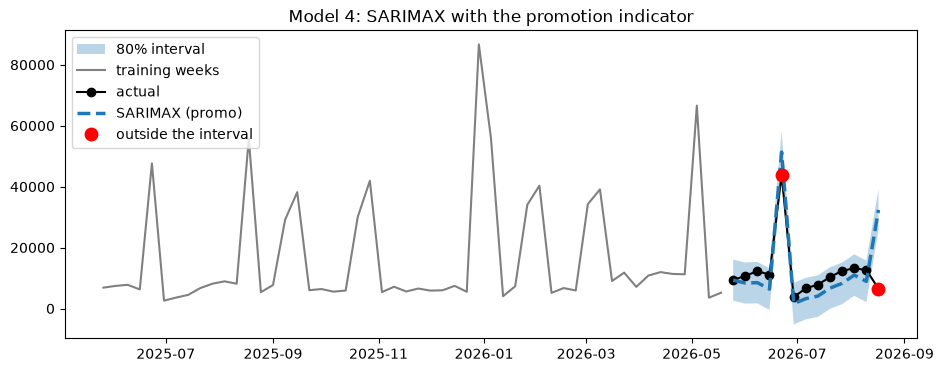

holdout weeks inside the 80% interval: 11 of 13


,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513
"ARMA(3, 0)",8224.031,10750.712,0.594
SARIMA,5785.208,11019.979,0.418
SARIMAX (promo),5168.848,8061.193,0.373


In [33]:
f_sarimax = sarimax.get_forecast(H, exog=X.loc[test.index])          # the forecast needs the 13 future promo values
forecasts["SARIMAX (promo)"] = 1000 * f_sarimax.predicted_mean.values
band_plot(f_sarimax, "SARIMAX (promo)", "Model 4: SARIMAX with the promotion indicator",
          save_as=RESULTS / "nb_final_forecast.png")
score_table(forecasts).round(3)

**What to see.**
- A promotion week adds about **30,000 orders** (p-value below 0.001). The AIC drops sharply (same series, same differences, so the two AICs can be compared). The residuals still pass Ljung-Box.
- Holdout: MASE **0.373**, the best so far, and 11 of 13 weeks fall inside the 80% interval (about 10 are expected). The two misses are the promotion week, slightly overestimated, and the last week (Part 8).
- The lower edge of the interval dips below 0 in a few weeks, which is impossible for orders. The model assumes normal, symmetric errors. That is a known limitation for a series with large peaks.
- The gain on the holdout is smaller than the AIC suggests. The holdout has **only one promotion week**, and it fell in the same week as last year, so the SARIMA already caught it. Part 7 tests the models on more promotions.

# Model 5: SARIMAX, adding the holiday calendar

**The question.** The holiday rows are known in advance too. Do they add anything?

In [34]:
X2 = pd.concat([X, holidays], axis=1)           # promo + the three holiday columns
print("holidays in the holdout weeks:", int(holidays.loc[test.index].values.sum()))
sarimax2 = SARIMAX(train_k, exog=X2.loc[train.index], order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
print(pd.DataFrame({"effect (orders)": 1000 * sarimax2.params[X2.columns], "p-value": sarimax2.pvalues[X2.columns]}).round(3))
forecasts["SARIMAX (promo + holidays)"] = 1000 * sarimax2.get_forecast(H, exog=X2.loc[test.index]).predicted_mean.values
score_table(forecasts).round(3)

holidays in the holdout weeks: 0


                          effect (orders)  p-value
promo                           29859.043    0.000
Maundy Thursday Calendar        -3957.828    0.460
New Year Calendar                 831.051    0.675
Easter Monday Calendar            456.971    0.916


,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513
"ARMA(3, 0)",8224.031,10750.712,0.594
SARIMA,5785.208,11019.979,0.418
SARIMAX (promo),5168.848,8061.193,0.373
SARIMAX (promo + holidays),5261.392,8290.491,0.380


**What to see.** None of the holiday effects is significant (p-values 0.46-0.92), each holiday happened only three times in training, and none falls in the holdout. The MASE gets slightly worse (0.380 vs 0.373). A larger model is not always better, so **we drop the holidays. Model 4, SARIMAX with the promotion indicator, is our final model.**

# Part 6: The benchmark table

All models on the same 13 holdout weeks, from simple to complex.

In [35]:
table = score_table(forecasts)
table.to_csv(RESULTS / "nb_benchmark_table.csv")            # saved for the slides
table.round(3)

,MAE,RMSE,MASE
method,,,
mean,7885.245,10159.446,0.570
naive,7392.554,11908.616,0.534
drift,8524.952,12684.928,0.616
seasonal naive,7104.923,14138.717,0.513
"ARMA(3, 0)",8224.031,10750.712,0.594
SARIMA,5785.208,11019.979,0.418
SARIMAX (promo),5168.848,8061.193,0.373
SARIMAX (promo + holidays),5261.392,8290.491,0.380


**What to see.** Every step down the list adds one idea. The **season** (SARIMA) and the **promotion indicator** (SARIMAX) are the two ideas that pay off. The ARMA alone does not beat the baselines, and the holidays add nothing. The final model has MASE 0.373 against 0.513 for the best baseline (seasonal naive), a 27% lower error.

# Part 7: Is one holdout enough? A rolling-origin check (Lecture 10)

**The question.** One holdout is one draw, and ours has only one promotion week. Lecture 10's answer is a rolling origin: train, forecast the next 13 weeks, move the origin forward, and repeat. We do it **inside the 144 training weeks** (origins after week 105, 118 and 131), so the holdout stays untouched. The orders (p, q, P, Q) are those chosen above; the coefficients are re-estimated in every window.

In [36]:
rows = []
for n0 in [len(train) - 3 * H, len(train) - 2 * H, len(train) - H]:     # the three forecast origins
    tr, te = train.iloc[:n0], train.iloc[n0:n0 + H]                       # train on weeks 1..n0, test the next 13
    tr_k = tr / 1000
    fc = {"seasonal naive": tr.iloc[-52:].iloc[:H].values,
          "ARMA(3, 0)": SARIMAX(tr_k, order=arma_order, trend="c").fit(disp=False).get_forecast(H).predicted_mean,
          "SARIMA": SARIMAX(tr_k, order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
                    .get_forecast(H).predicted_mean,
          "SARIMAX (promo)": SARIMAX(tr_k, exog=X.loc[tr.index], order=sarima_order, seasonal_order=seasonal_order)
                             .fit(disp=False).get_forecast(H, exog=X.loc[te.index]).predicted_mean}
    for name, f in fc.items():
        f = f if name == "seasonal naive" else 1000 * f                   # back from thousands to orders
        rows.append({"origin (training weeks)": n0, "method": name, "MASE": mase(te, f, tr)})
    print("origin", n0, "-> promotion weeks in the 13 test weeks:", promo[te.index].sum())

cv = pd.DataFrame(rows).pivot(index="method", columns="origin (training weeks)", values="MASE")
cv["mean MASE"] = cv.mean(axis=1)
cv.sort_values("mean MASE").round(3)

origin 105 -> promotion weeks in the 13 test weeks: 4


origin 118 -> promotion weeks in the 13 test weeks: 4


origin 131 -> promotion weeks in the 13 test weeks: 3


origin (training weeks),105,118,131,mean MASE
method,,,,
SARIMAX (promo),0.324,0.291,0.293,0.302
seasonal naive,1.066,0.287,0.589,0.648
SARIMA,1.345,0.495,0.718,0.853
"ARMA(3, 0)",1.039,1.418,0.864,1.107


**What to see.** Each test window contains 3-4 promotions, against only one in the holdout. Here the promotion indicator makes a big difference: **SARIMAX (promo)** has by far the lowest mean MASE (0.30, against 0.65 for the seasonal naive and 0.85 for the SARIMA without the indicator). It is the best model in two of the three windows and practically tied with the seasonal naive in the third (0.291 vs 0.287). When promotions move to new weeks, a model that only copies last year goes wrong. The ranking supports the choice of Model 4 on more than one holdout.

# Part 8: Where is the final forecast wrong?

**The question.** What can we learn from the weeks where the forecast misses? We use the exception flags here, only to *understand* errors after the fact.

In [37]:
errors = pd.DataFrame({"actual": test, "forecast": forecasts["SARIMAX (promo)"], "promo": promo[test.index],
                       "exception flag": exception[test.index]})
errors["error"] = errors["actual"] - errors["forecast"]
errors.round(0)

,actual,forecast,promo,exception flag,error
date,,,,,
2026-05-25,9372.0,9323.0,0,0.0,49.0
2026-06-01,10714.0,8368.0,0,0.0,2345.0
2026-06-08,12298.0,8491.0,0,0.0,3806.0
2026-06-15,11098.0,6361.0,0,0.0,4736.0
2026-06-22,43910.0,51329.0,1,0.0,-7419.0
2026-06-29,3758.0,1615.0,0,1.0,2143.0
2026-07-06,6631.0,3243.0,0,1.0,3388.0
2026-07-13,7850.0,4093.0,0,1.0,3757.0
2026-07-20,10322.0,6707.0,0,0.0,3616.0


In [38]:
worst = errors["error"].abs().idxmax()
last_year = worst - pd.Timedelta(weeks=52)
print("largest miss:", worst.date(), "| error", round(errors.loc[worst, "error"]), "| promotion this year:", promo[worst])
print("the same week last year:", last_year.date(), "| orders", round(y[last_year]), "| promotion:", promo[last_year])

largest miss: 2026-08-17 | error -25848 | promotion this year: 0
the same week last year: 2025-08-18 | orders 55841 | promotion: 1


**What to see.** In 11 of the other 12 weeks the forecast is **too low**, by about 2,000-5,000 orders. This summer's base level (about 10,000-13,000) is higher than last summer's (about 6,000-9,000), and the seasonal difference partly copies last year's lower level. The orders had already risen to about 11,000 in the last training weeks. The largest miss by far is the **last week (W34 2026)**. The model expects about 32,000, but only about 6,500 came. The reason: W34 last year was a large promotion week (55,841 orders, far above the average promotion effect). The seasonal part (D = 1) carries the part of last year's peak that the promotion indicator does not explain into this year, even though there is no promotion this year.

**Is the last week even complete?** Our milk and skyr series both drop in that week. We check all dense series.

In [39]:
orders_all = raw[raw["Key Figure"] == "Orders Weekly"].set_index(["Customer", "Product"])[week_cols]
dense = orders_all[(orders_all[train_weeks] == 0).mean(axis=1) <= 0.05]       # the 36 dense series
for i in [-3, -2, -1]:                                                         # the last three weeks of the data
    ratio = dense[week_cols[i]] / dense[week_cols[i - 4:i]].mean(axis=1)      # this week / mean of the 4 weeks before
    print(week_cols[i], "| median ratio:", round(ratio.median(), 2), "| share of series below 75%:", round((ratio < 0.75).mean(), 2))

W32 2026 | median ratio: 1.1 | share of series below 75%: 0.19
W33 2026 | median ratio: 1.01 | share of series below 75%: 0.28
W34 2026 | median ratio: 0.52 | share of series below 75%: 0.94


In [40]:
# the scores without the last week (12 holdout weeks) - only a check, it does not change our choice
pd.Series({m: mase(test.iloc[:-1], f[:-1], train) for m, f in forecasts.items()}, name="MASE without W34 2026").round(3)

mean                          0.560
naive                         0.571
drift                         0.645
seasonal naive                0.259
ARMA(3, 0)                    0.587
SARIMA                        0.225
SARIMAX (promo)               0.249
SARIMAX (promo + holidays)    0.251
Name: MASE without W34 2026, dtype: float64

**What to see.** In W34 2026, **94% of the dense series** fall below 75% of the weeks before (median ratio 0.52). In the two weeks before, it is only 19-28%. A drop in almost every customer and product at the same time looks like an **incomplete last week** (data pulled in the middle of the week) rather than real demand. Arla should confirm this. We noticed it only after scoring the holdout, so we keep the 13-week result as our main result and show the 12-week scores only as a check. Without that week the seasonal models improve a lot, while naive and drift do not. The three seasonal models are then very close (SARIMA 0.225, SARIMAX 0.249, seasonal naive 0.259), because the one holdout promotion fell in the same week as last year. That is why Part 7 matters.

# Part 9: Checking a cleaning decision: Manual Cleaned History

**The question.** In Part 4 we kept the raw orders. What if we had replaced them with the planners' cleaned values in the training weeks? The holdout is still scored against the raw orders.

In [41]:
train_clean = train.where(mch[train.index] == 0, mch[train.index])     # use the cleaned value where there is one
print("training weeks changed:", int((train_clean != train).sum()))
sarimax_clean = SARIMAX(train_clean / 1000, exog=X.loc[train.index], order=sarima_order,
                        seasonal_order=seasonal_order).fit(disp=False)
fc_clean = 1000 * sarimax_clean.get_forecast(H, exog=X.loc[test.index]).predicted_mean
print("SARIMAX (promo) MASE: raw training data", round(mase(test, forecasts["SARIMAX (promo)"], train), 3),
      "| cleaned training data", round(mase(test, fc_clean, train), 3))

training weeks changed: 35


SARIMAX (promo) MASE: raw training data 0.373 | cleaned training data 0.396


**What to see.** With the cleaned history the MASE gets worse (0.396 vs 0.373). Replacing 13 promotion peaks with a baseline confuses the promotion indicator. The decision to keep the raw orders holds.

# Part 10: What if we forecast half a year (26 weeks) ahead?

**The question.** Our holdout is 13 weeks. Arla also plans further ahead, for example production and capacity for the next half year. Does the forecast still work 26 weeks ahead, and what changes?

We keep the **same model orders** as in Models 3-4, so only the horizon changes. (In a real project we would redo the AIC search on the shorter training set.) Three checks:

1. The **same target weeks** (our 13 holdout weeks), forecast from 13 weeks further back.
2. A **26-week holdout**: the scores and the width of the 80% interval.
3. The **error by horizon** over several forecast origins, as in Part 7.

In [42]:
H26 = 26
train26, test26 = split_holdout(y, H26)                  # now the last 26 weeks are the holdout
print("training:", len(train26), "weeks, to", train26.index[-1].date(), "| holdout:", test26.index[0].date(), "to", test26.index[-1].date())
print("promotion weeks in the 26 holdout weeks:", promo[test26.index].sum())

train26_k = train26 / 1000
sarima26 = SARIMAX(train26_k, order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
sarimax26 = SARIMAX(train26_k, exog=X.loc[train26.index], order=sarima_order, seasonal_order=seasonal_order).fit(disp=False)
f_sarimax26 = sarimax26.get_forecast(H26, exog=X.loc[test26.index])     # needs the promotion plan of all 26 weeks

forecasts26 = {"seasonal naive": train26.iloc[-52:].iloc[:H26].values,   # the same 26 weeks one year earlier
               "SARIMA": 1000 * sarima26.get_forecast(H26).predicted_mean.values,
               "SARIMAX (promo)": 1000 * f_sarimax26.predicted_mean.values}

training: 131 weeks, to 2026-02-16 | holdout: 2026-02-23 to 2026-08-17
promotion weeks in the 26 holdout weeks: 4


**Check 1: the same weeks, forecast from further away.** The last 13 weeks of the 26-week holdout are exactly our 13 holdout weeks. So we can compare the forecasts of the same weeks made 1-13 weeks ahead (Models 1-4) and 14-26 weeks ahead (now).

In [43]:
pd.DataFrame({"MAE, 1-13 weeks ahead": {m: mae(test, forecasts[m]) for m in forecasts26},
              "MAE, 14-26 weeks ahead": {m: mae(test, f[-H:]) for m, f in forecasts26.items()}}).round(0)

,"MAE, 1-13 weeks ahead","MAE, 14-26 weeks ahead"
seasonal naive,7105.0,7105.0
SARIMA,5785.0,6548.0
SARIMAX (promo),5169.0,4928.0


**What to see.** The **seasonal naive** gives exactly the same forecast. It copies the same weeks from last year, however far ahead (up to 52 weeks). **SARIMA gets worse** (5,785 → 6,548). Its AR(3) part learns from the last few weeks, and 14-26 weeks ahead that information has faded, so only the season is left. **SARIMAX stays at the same level** (5,169 vs 4,928). Most of what it knows comes from the promotion plan and the season, not from the last few weeks. That only holds if the promotion plan is known half a year ahead.

**Check 2: the 26-week holdout.** MASE on all 26 weeks, the MAE of each half, and the 80% interval of SARIMAX.

In [44]:
rows = []
for m, f in forecasts26.items():
    rows.append({"method": m, "MASE (26 weeks)": mase(test26, f, train26),
                 "MAE weeks 1-13": mae(test26[:13], f[:13]), "MAE weeks 14-26": mae(test26[13:], f[13:])})
pd.DataFrame(rows).set_index("method").round(3)

,MASE (26 weeks),MAE weeks 1-13,MAE weeks 14-26
method,,,
seasonal naive,0.554,8078.215,7104.923
SARIMA,0.598,9846.848,6547.528
SARIMAX (promo),0.326,4011.601,4927.628


width of the 80% interval: 1 week ahead 13957 | 13 weeks 14206 | 26 weeks 14198
holdout weeks inside the 80% interval: 22 of 26


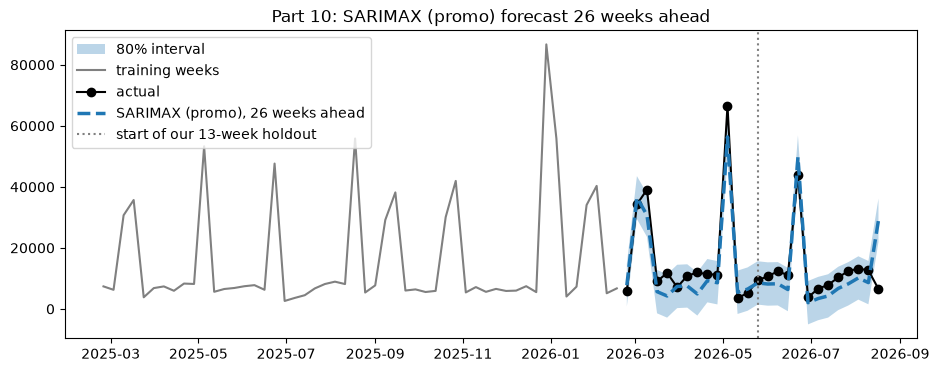

In [45]:
ci26 = 1000 * f_sarimax26.conf_int(alpha=0.2)                          # the 80% interval, in orders
width = ci26.iloc[:, 1] - ci26.iloc[:, 0]
inside = (test26 >= ci26.iloc[:, 0]) & (test26 <= ci26.iloc[:, 1])
print("width of the 80% interval: 1 week ahead", round(width.iloc[0]), "| 13 weeks", round(width.iloc[12]),
      "| 26 weeks", round(width.iloc[25]))
print("holdout weeks inside the 80% interval:", int(inside.sum()), "of", H26)

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(test26.index, ci26.iloc[:, 0], ci26.iloc[:, 1], alpha=0.3, label="80% interval")
ax.plot(train26.iloc[-52:], color="grey", label="training weeks")
ax.plot(test26, marker="o", color="black", label="actual")
ax.plot(test26.index, forecasts26["SARIMAX (promo)"], ls="--", lw=2.5, label="SARIMAX (promo), 26 weeks ahead")
ax.axvline(test.index[0], color="grey", ls=":", label="start of our 13-week holdout")
ax.set_title("Part 10: SARIMAX (promo) forecast 26 weeks ahead"); ax.legend(loc="upper left")
fig.savefig(RESULTS / "nb_26_week_forecast.png", dpi=130, bbox_inches="tight")
plt.show()

**What to see.** The 80% interval **hardly widens**: it is about 14,000 orders wide at 1, 13 and 26 weeks ahead. The uncertainty of the AR part levels off after a few weeks, and the seasonal part (D = 1) only adds uncertainty after 52 weeks, when the model has to copy its own forecasts. So the interval assumes that this year looks like last year. It does not include the risk of a change in level, like the higher base level of summer 2026. Still, 22 of the 26 weeks fall inside.

The MASE of 0.326 is lower than the 0.373 of the 13-week holdout, but that does **not** mean that 26 weeks ahead is easier. The weeks are different (February-May, with 4 promotion weeks that SARIMAX hits), and so is the MASE scale (a different training set). Only Check 1 compares the same weeks. The price of the longer holdout: 131 training weeks instead of 144, and after the seasonal difference only 79 weeks to estimate from.

**Check 3: the error by horizon.** One holdout is one draw (Part 7). We forecast 26 weeks ahead from five origins and average the absolute error for each horizon h = 1, ..., 26.

origin 110 (training to 2025-09-22) -> promotion weeks in the next 26: 8


origin 116 (training to 2025-11-03) -> promotion weeks in the next 26: 7


origin 122 (training to 2025-12-15) -> promotion weeks in the next 26: 7


origin 126 (training to 2026-01-12) -> promotion weeks in the next 26: 6


origin 131 (training to 2026-02-16) -> promotion weeks in the next 26: 4


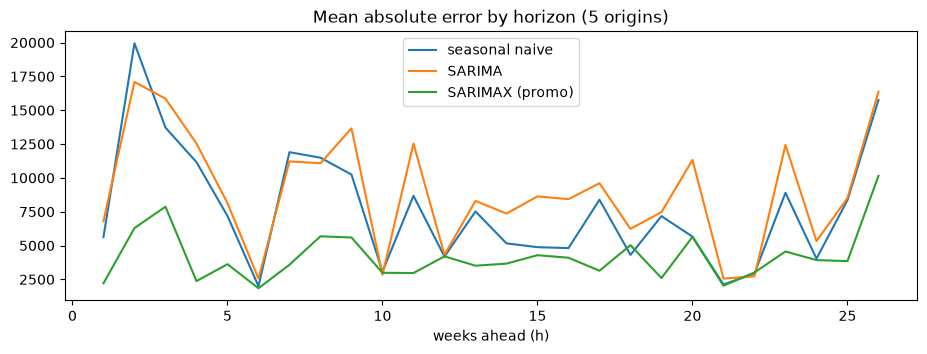

,h 1-4,h 5-13,h 14-26
seasonal naive,12612.0,7364.0,6344.0
SARIMA,13074.0,8296.0,8229.0
SARIMAX (promo),4686.0,3777.0,4306.0


In [46]:
origins = [110, 116, 122, 126, 131]          # training weeks; 131 is the 26-week holdout above
abs_err = {"seasonal naive": [], "SARIMA": [], "SARIMAX (promo)": []}
for n0 in origins:
    tr, te = y.iloc[:n0], y.iloc[n0:n0 + H26]
    tr_k = tr / 1000
    fc = {"seasonal naive": tr.iloc[-52:].iloc[:H26].values,
          "SARIMA": 1000 * SARIMAX(tr_k, order=sarima_order, seasonal_order=seasonal_order)
                    .fit(disp=False).get_forecast(H26).predicted_mean.values,
          "SARIMAX (promo)": 1000 * SARIMAX(tr_k, exog=X.loc[tr.index], order=sarima_order, seasonal_order=seasonal_order)
                             .fit(disp=False).get_forecast(H26, exog=X.loc[te.index]).predicted_mean.values}
    for m in abs_err:
        abs_err[m].append(np.abs(te.values - fc[m]))
    print("origin", n0, f"(training to {tr.index[-1].date()}) -> promotion weeks in the next 26:", promo[te.index].sum())

mean_err = pd.DataFrame({m: np.mean(e, axis=0) for m, e in abs_err.items()}, index=np.arange(1, H26 + 1))
mean_err.plot(figsize=(11, 3.5), title="Mean absolute error by horizon (5 origins)", xlabel="weeks ahead (h)")
plt.show()
pd.DataFrame({"h 1-4": mean_err.loc[1:4].mean(), "h 5-13": mean_err.loc[5:13].mean(),
              "h 14-26": mean_err.loc[14:26].mean()}).round(0)

**What to see.** For SARIMAX the error **does not grow clearly with the horizon** (about 4,700, 3,800 and 4,300 for h = 1-4, 5-13 and 14-26). The curve jumps up and down, because the errors depend mostly on **which** weeks are forecast (the Christmas and promotion peaks), not on how far ahead. The model without the promotion plan (SARIMA) has about twice the error of SARIMAX 14-26 weeks ahead.

**Conclusion.** For this series, a half-year forecast works **if the promotion plan is known half a year ahead**. Without it, the error roughly doubles. The 80% interval does not show the extra risk of a longer horizon, such as a change in level, so it understates the uncertainty. We keep the 13-week holdout as our main result (more training data, one quarter) and use the 26-week check as a robustness check.

# Summary: five slides in five minutes

1. **Series and why.** Discount 1 – Product 3 (Skyr Flavoured). We chose it on the training weeks only: dense (no zero weeks), with promotions in 28% of the weeks, and the largest such series. 14 of the 50 series are too sparse for these methods.
2. **Data and variables.** The data was checked (no duplicates or missing values) and reshaped from wide to one row per week. Target: raw `Orders Weekly`. Promotions are used only as a yes/no indicator (known in advance, size not used). Exception weeks are kept but not used as input (unknown in advance). Manual Cleaned History is not used, because it removes the promotion peaks. Seasonality Calendar 3 is all zeros, and 1-8 have no stated meaning. The holidays were tested and dropped.
3. **Approach.** Train 144 weeks, holdout the last 13 weeks (one quarter). From simple to complex: baselines → ARMA → SARIMA → SARIMAX. Orders from ACF/PACF and the AIC on the training weeks, then a residual check (Ljung-Box).
4. **Results (MASE on the holdout).** Best baseline 0.513 (seasonal naive), ARMA 0.594, SARIMA 0.418, **SARIMAX with the promotion indicator 0.373**. 11 of 13 weeks fall in the 80% interval. A rolling-origin check with more promotions confirms SARIMAX (promo) as clearly the best.
5. **Insight and limitations.** Knowing the promotion plan is the most valuable information. Promotions add about 30,000 orders a week. The largest miss comes from the seasonal part copying last year's unusually big promotion week, and the last data week looks incomplete in almost all series. Limitations: only 2.8 years of data, every promotion is assumed to have the same effect, and one holdout is one draw. A 26-week check (Part 10): SARIMAX keeps its accuracy half a year ahead when the promotion plan is known; without it the error roughly doubles. Next steps: different effects per promotion type, the week after a promotion, and methods for the sparse series.

Saved files: `results/nb_benchmark_table.csv`, `results/nb_final_forecast.png` and `results/nb_26_week_forecast.png`.